
# Hands-on 2: MLOps — Model Experimentation & Tracking

## Implementasi MLflow dan Scikit-learn untuk Deteksi Tumor Ganas

**Studi Kasus:** Breast Cancer Wisconsin Classification

In [ ]:
!pip install -q "mlflow>=3" scikit-learn pandas matplotlib requests

## Struktur Proyek & Setup

> Catatan: langkah di bawah adalah cara menjalankan di **komputer lokal (terminal)**. Pada notebook Colab ini, tracking server diganti dengan SQLite lokal (lihat sel setup di bawah), sehingga langkah ini tidak perlu dijalankan di Colab.

```bash
python -m venv .venv && source .venv/bin/activate
pip install "mlflow>=3" scikit-learn pandas matplotlib requests
pip freeze > requirements.txt          # kunci environment (diuji: MLflow 3.17)

# Terminal 1: tracking server (metadata → SQLite, file → folder lokal)
mlflow server --backend-store-uri sqlite:///mlflow.db \
              --default-artifact-root ./mlartifacts --port 5000

# Terminal 2: semua script akan membaca variabel ini
export MLFLOW_TRACKING_URI=http://127.0.0.1:5000
```

In [ ]:
import os, warnings
warnings.filterwarnings("ignore")
import mlflow, mlflow.sklearn

os.makedirs("data", exist_ok=True)
mlflow.set_tracking_uri("sqlite:///mlflow.db")   # pengganti "mlflow server" + export di Colab
print("MLflow", mlflow.__version__)

MLflow 3.17.0


## L1 — Data: Split Tetap + Versi Data (Hash)

In [ ]:
import hashlib, pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

mlflow.set_experiment("bc-malignant-detection")

df = load_breast_cancer(as_frame=True).frame
df["target"] = 1 - df["target"]                       # 1 = malignant (kelas positif)

# Sidik jari data: berubah satu nilai pun → hash berbeda
data_md5 = hashlib.md5(pd.util.hash_pandas_object(df, index=True).values).hexdigest()

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=42)
train_df.to_csv("data/train.csv", index=False)
test_df.to_csv("data/test.csv", index=False)          # test set: DIKUNCI sampai L6

In [ ]:
X_train, y_train = train_df.drop(columns="target"), train_df["target"]
X_test,  y_test  = test_df.drop(columns="target"),  test_df["target"]

# Objek Dataset MLflow → tampil di tab "Datasets" pada setiap run
train_ds = mlflow.data.from_pandas(train_df, source="data/train.csv",
                                   name="bc-train", targets="target")

COMMON_TAGS = {"data_md5": data_md5, "split_seed": "42", "dataset": "sklearn-breast-cancer"}

## Fungsi Logging Standar run_experiment()

In [ ]:
import mlflow, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from mlflow.models import infer_signature

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = ["recall", "precision", "f1", "roc_auc"]

# fold identik utk semua run
def run_experiment(run_name, pipe, tags=None, note=""):
  with mlflow.start_run(run_name=run_name) as run:
    # (a) KONTEKS: tag, catatan hipotesis, versi data
    mlflow.set_tags({**COMMON_TAGS, "candidate": "true", **(tags or {})})
    mlflow.set_tag("mlflow.note.content", note)        # deskripsi run di UI
    mlflow.log_input(train_ds, context="training")
    # (b) PARAMETER: langkah pipeline + seluruh hyperparameter estimator
    mlflow.log_param("pipeline_steps", " -> ".join(pipe.named_steps))
    mlflow.log_params({f"clf__{k}": v for k, v in pipe[-1].get_params().items()})

    # (c) METRIK: mean & std dari 5-fold CV (bukan satu angka tunggal!)
    cv = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING)
    for m in SCORING:
      mlflow.log_metric(f"cv_{m}_mean", cv[f"test_{m}"].mean())
      mlflow.log_metric(f"cv_{m}_std",  cv[f"test_{m}"].std())
    mlflow.log_metric("fit_time_s", cv["fit_time"].mean())

    # (d) ARTEFAK DIAGNOSTIK: prediksi out-of-fold (tanpa menyentuh test set)
    y_oof = cross_val_predict(pipe, X_train, y_train, cv=CV)
    disp = ConfusionMatrixDisplay.from_predictions(
        y_train, y_oof, display_labels=["benign", "malignant"])
    mlflow.log_figure(disp.figure_, "plots/confusion_matrix_oof.png")
    plt.close(disp.figure_)
    mlflow.log_text(classification_report(y_train, y_oof, zero_division=0),
                    "reports/classification_report_oof.txt")

    # (e) MODEL: dilatih ulang di seluruh train set + signature & contoh input
    pipe.fit(X_train, y_train)
    signature = infer_signature(X_train, pipe.predict(X_train))
    info = mlflow.sklearn.log_model(pipe, name="model", signature=signature,
                                    input_example=X_train.head(3),
                                    skops_trusted_types=["sklearn.tree._tree.Tree"])  # utk DT/RF/GB
    mlflow.set_tag("model_uri", info.model_uri)        # models:/m-… (MLflow 3)
    return run.info.run_id

## L2 — Baseline: Seberapa Buruk "Tanpa Model"? (H1, H2)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

run_experiment("00-dummy-most-frequent",
    Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    tags={"stage": "baseline", "model_family": "dummy"},
    note="Batas bawah: selalu menebak kelas mayoritas (benign).")

run_experiment("01-logreg-noscale",
    Pipeline([("clf", LogisticRegression(max_iter=5000))]),
    tags={"stage": "baseline", "model_family": "logreg"},
    note="H1: model linear tanpa preprocessing.")

run_experiment("02-logreg-scaled",
    Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
    tags={"stage": "baseline", "model_family": "logreg"},
    note="H2: hanya menambah StandardScaler, variabel lain tetap.")

'9d81d9a8068e4743bef1bd7340aef905'

## L3 — Model Selection: Bandingkan Algoritma Sederhana

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

candidates = {
    "knn":  KNeighborsClassifier(n_neighbors=5),
    "tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "rf":   RandomForestClassifier(n_estimators=200, random_state=42),
    "gb":   GradientBoostingClassifier(random_state=42),
    "svc":  SVC(kernel="rbf", random_state=42),
}

for i, (family, clf) in enumerate(candidates.items(), start=3):
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    run_experiment(f"{i:02d}-{family}-default", pipe,
                   tags={"stage": "model-selection", "model_family": family},
                   note="Hyperparameter default; preprocessing identik untuk semua.")

## L4 — Hyperparameter Tuning dengan Nested Runs (H3)

In [ ]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=42))])
grid = {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001]}   # 12 kombinasi
gs = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit="recall", n_jobs=-1)

with mlflow.start_run(run_name="10-svc-gridsearch",
                      tags={**COMMON_TAGS, "stage": "tuning", "model_family": "svc",
                            "candidate": "true"}):
    mlflow.log_input(train_ds, context="training")
    mlflow.log_dict(grid, "search_space.json")                  # ruang pencarian = artefak
    gs.fit(X_train, y_train)
    res = gs.cv_results_

    for i, params in enumerate(res["params"]):                  # 1 trial = 1 child run
        with mlflow.start_run(run_name=f"svc-trial-{i:02d}", nested=True):
            mlflow.log_params(params)
            mlflow.log_metrics({f"cv_{m}_mean": res[f"mean_test_{m}"][i] for m in SCORING})
            mlflow.log_metrics({f"cv_{m}_std":  res[f"std_test_{m}"][i]  for m in SCORING})
    b = gs.best_index_

    # parent = ringkasan terbaik
    mlflow.log_params(gs.best_params_)
    mlflow.log_metrics({f"cv_{m}_mean": res[f"mean_test_{m}"][b] for m in SCORING})
    mlflow.log_metrics({f"cv_{m}_std":  res[f"std_test_{m}"][b]  for m in SCORING})
    info = mlflow.sklearn.log_model(gs.best_estimator_, name="model",
        signature=infer_signature(X_train, gs.best_estimator_.predict(X_train)),
        input_example=X_train.head(3))
    mlflow.set_tag("model_uri", info.model_uri)

## L5 — Analisis Programatik: Pilih Kandidat Terbaik

In [ ]:
import mlflow

runs = mlflow.search_runs(
    experiment_names=["bc-malignant-detection"],
    filter_string=(
        "tags.candidate = 'true' "                       # hanya run yang punya model
        "and metrics.cv_precision_mean >= 0.90"          # satisficing metric
    ),
    order_by=["metrics.cv_recall_mean DESC",             # optimizing metric
              "metrics.cv_f1_mean DESC"],                # tie-breaker
)

cols = ["tags.mlflow.runName", "tags.model_family",
        "metrics.cv_recall_mean", "metrics.cv_recall_std", "metrics.cv_precision_mean"]
print(runs[cols].head(5).to_string(index=False))

best_run_id    = runs.iloc[0]["run_id"]
best_model_uri = runs.iloc[0]["tags.model_uri"]          # models:/m-…
print("Kandidat terpilih:", runs.iloc[0]["tags.mlflow.runName"], best_run_id)

tags.mlflow.runName tags.model_family  metrics.cv_recall_mean  metrics.cv_recall_std  metrics.cv_precision_mean
  10-svc-gridsearch               svc                0.964706               0.028818                   0.971092
   02-logreg-scaled            logreg                0.952941               0.039896                   0.977143
      06-gb-default                gb                0.947059               0.034300                   0.964631
     07-svc-default               svc                0.947059               0.034300                   0.976946
      05-rf-default                rf                0.935294               0.039019                   0.963759
Kandidat terpilih: 10-svc-gridsearch 0f07838ecd1f48338672a171842afdee


## L6 — Evaluasi Final di Test Set (Hanya Sekali)

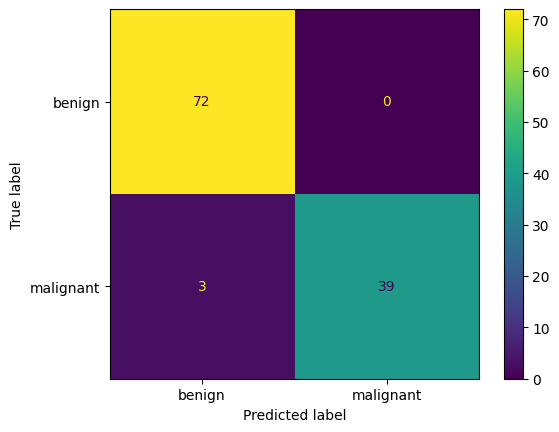

In [ ]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay

model = mlflow.sklearn.load_model(best_model_uri)
y_pred = model.predict(X_test)
score = (model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba")
        else model.decision_function(X_test))

test_metrics = {
    "test_recall":    recall_score(y_test, y_pred),
    "test_precision": precision_score(y_test, y_pred),
    "test_f1":        f1_score(y_test, y_pred),
    "test_roc_auc":   roc_auc_score(y_test, score),
}

with mlflow.start_run(run_id=best_run_id):              # tambahkan ke run yang SAMA
    mlflow.log_metrics(test_metrics)
    mlflow.log_input(mlflow.data.from_pandas(test_df, source="data/test.csv",
                     name="bc-test", targets="target"), context="testing")
    disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                     display_labels=["benign", "malignant"])
    mlflow.log_figure(disp.figure_, "plots/confusion_matrix_test.png")
    mlflow.set_tag("test_evaluated", "true")

## L7 — Model Registry + Quality Gate Otomatis

In [ ]:
from mlflow import MlflowClient
client, NAME = MlflowClient(), "bc-malignant-classifier"

mv = mlflow.register_model(best_model_uri, NAME)                     # → versi baru
client.update_model_version(NAME, mv.version,
    description=f"Dipilih otomatis: max cv_recall dgn precision>=0.90. data_md5={data_md5}")
client.set_model_version_tag(NAME, mv.version, "data_md5", data_md5)
client.set_registered_model_alias(NAME, "challenger", mv.version)

def champion_recall():
  try:
      champ = client.get_model_version_by_alias(NAME, "champion")
      return client.get_run(champ.run_id).data.metrics["test_recall"]
  except Exception:                                   # belum ada champion
      return -1.0

MIN_PRECISION, MARGIN = 0.90, 0.005
passed = (test_metrics["test_precision"] >= MIN_PRECISION and
          test_metrics["test_recall"] >= champion_recall() + MARGIN)

client.set_model_version_tag(NAME, mv.version, "validation_status",
                             "approved" if passed else "rejected")
if passed:
    client.set_registered_model_alias(NAME, "champion", mv.version)   # promosi

Successfully registered model 'bc-malignant-classifier'.
Created version '1' of model 'bc-malignant-classifier'.


## L8 — Serving Model dari Registry

Serving memuat model berdasarkan **alias**, bukan path file atau nomor versi.

Di komputer lokal, jalankan di terminal:

```bash
export MLFLOW_TRACKING_URI=http://127.0.0.1:5000
mlflow models serve -m "models:/bc-malignant-classifier@champion" \
                    -p 5001 --env-manager local
```

Di Colab, server dijalankan di background lewat Python pada sel berikut.

In [ ]:
import subprocess, time
env = {**os.environ, "MLFLOW_TRACKING_URI": "sqlite:///mlflow.db"}
srv = subprocess.Popen(["mlflow", "models", "serve", "-m", "models:/bc-malignant-classifier@champion",
                        "-p", "5001", "--env-manager", "local"],
                       env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(30)   # tunggu server siap

In [ ]:
import requests

payload = {"dataframe_split": X_test.head(3).to_dict(orient="split")}
r = requests.post("http://127.0.0.1:5001/invocations", json=payload)
print(r.json())                     # {"predictions": [0, 1, 0]}  (1 = malignant)

# Atau langsung di aplikasi Python (batch scoring)
model = mlflow.pyfunc.load_model("models:/bc-malignant-classifier@champion")
preds = model.predict(X_test)
# input divalidasi terhadap signature

srv.terminate()   # matikan server setelah selesai

{'predictions': [0, 1, 0]}


## L9 — Reproduce: Dari Model di Produksi Kembali ke Asal-usulnya

In [ ]:
champ = client.get_model_version_by_alias("bc-malignant-classifier", "champion")
run = client.get_run(champ.run_id)

print("Run        :", run.info.run_name, run.info.run_id)
print("Git commit :", run.data.tags.get("mlflow.source.git.commit"))
print("Data md5   :", run.data.tags["data_md5"])
print("Params     :", {k: v for k, v in run.data.params.items() if k.startswith("clf__")})
print("Metrics    :", {k: round(v, 3) for k, v in run.data.metrics.items()})

# 1) Pastikan data saat ini identik dengan data training
assert data_md5 == run.data.tags["data_md5"], "Data berbeda → hasil tidak akan sama!"

# 2) Unduh artefak (model, requirements.txt, plot) untuk audit
path = mlflow.artifacts.download_artifacts(run_id=champ.run_id, artifact_path="model")
print(open(f"{path}/requirements.txt").read())

Run        : 10-svc-gridsearch 0f07838ecd1f48338672a171842afdee
Git commit : None
Data md5   : ee5481ad12c0896439e993aacc9e8d50
Params     : {'clf__C': '10', 'clf__gamma': 'scale'}
Metrics    : {'cv_recall_mean': 0.965, 'cv_precision_mean': 0.971, 'cv_f1_mean': 0.967, 'cv_roc_auc_mean': 0.993, 'cv_recall_std': 0.029, 'cv_precision_std': 0.018, 'cv_f1_std': 0.011, 'cv_roc_auc_std': 0.006, 'test_recall': 0.929, 'test_precision': 1.0, 'test_f1': 0.963, 'test_roc_auc': 0.993}


mlflow==3.17.0
lz4==4.4.5
numpy==2.1.3
pandas==2.2.3
polars==1.35.2
psutil==5.9.5
pytest==8.4.2
scikit-learn==1.6.1
scipy==1.16.3
skops==0.16.0
